# Clinical indices - definitions of layer 3

The clinical indices of a breath and of a PEEP step (`fasteit.features`), computed on 11 tidal recordings and four
decremental PEEP trials (patients A and B, supine and park bench, volume control). Each section gives the definition
with its source, runs the fastEIT function and states the decision; the table at the end maps each decision to the
code.

| § | Index |
|---|-------|
| 1 | EELI and TIV of a breath |
| 2 | Distribution of ventilation: share by region, GI, centre of ventilation |
| 3 | Compliance, global and by region |
| 4 | PEEP trials: Costa collapse and overdistension, changes between steps |
| 5 | Decisions |

EIT values are in arbitrary units, pressures in cmH2O, volumes in mL. The recordings are not in the repository.

*Research use only - not a medical device.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fasteit.features import peep_trial_features, tidal_features
from fasteit.features.breath_indices import centre_of_ventilation, global_inhomogeneity
from fasteit.features.costa import collapse_and_overdistension
from fasteit.models import RecordingContext
from fasteit.parsers.loader import load_data
from fasteit.preprocessing import preprocess
from fasteit.segmentation import segment_peep_trial

TEST_FILES = Path("../src/fasteit/test_files")
TIDAL_FILES = sorted(p for p in TEST_FILES.glob("*.bin") if "PEEP_trial" not in p.name)
TRIAL_FILES = sorted(TEST_FILES.glob("*PEEP_trial*.bin"))
SET_VT = {"A": 550, "B": 400}  # mL, set in volume control, the same in every step

BLUE, ORANGE, GREY = "#3987e5", "#e8730c", "#9a9a9a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "font.size": 9})

def summary_value(features, feature, region="global"):
    """A value of the summary of a PEEP trial (long table: region, feature, value)."""
    summary = features.summary
    return summary[(summary.region == region) & (summary.feature == feature)].value.iloc[0]


tidal = {p.stem: tidal_features(preprocess(load_data(p))) for p in TIDAL_FILES}
trials = {}
for p in TRIAL_FILES:
    name = p.stem.replace("PEEP_trial_", "")
    context = RecordingContext(protocol="peep_trial", tidal_volume_ml=SET_VT[name[0]])
    trials[name] = peep_trial_features(segment_peep_trial(preprocess(load_data(p), context=context)))
print(len(tidal), "tidal recordings,", len(trials), "PEEP trials")

11 tidal recordings, 4 PEEP trials


## 1. EELI and TIV of a breath

On the global signal inside the lung mask, at the frames of the layer 2 breath (one sample, no averaging), as in TREND
(Frerichs et al., Thorax 2017, DOI: 10.1136/thoraxjnl-2016-208357) and eitprocessing (v1.8.8, `EELI`, `TIV`,
"inspiratory" TIV):

- **EELI** = signal at the end-expiratory valley at the start of the breath (the same moment as its PEEP);
- **TIV** = signal at the end-inspiratory peak minus signal at the start.

The indices are in `features.breaths`; times and quality are in `recording.breaths`, joined on `breath_id`:

In [2]:
example = tidal["patient01_rec03"]
times = example.recording.breaths[["breath_id", "start_time", "peak_time", "is_valid"]]
times.merge(example.breaths[["breath_id", "eeli", "tiv"]], on="breath_id").head().round(2)

,breath_id,start_time,peak_time,is_valid,eeli,tiv
0,0,2.06,3.00,True,451.16,3292.19
1,1,3.98,4.92,True,351.87,3262.81
2,2,5.88,6.78,True,389.71,3281.95
3,3,7.68,8.54,True,507.65,3306.27
4,4,9.48,10.36,True,548.46,3181.52


## 2. Distribution of ventilation

From the **tidal image** of each breath (each pixel at the peak minus at the start, inside the lung mask):

- **share of a region** = TIV of the region / TIV of the lung (a ratio of sums);
- **GI** = Σ|pixel - median| / Σ pixel over the lung pixels (Zhao et al., Intensive Care Med 2009, DOI:
  10.1007/s00134-009-1589-y);
- **centre of ventilation** = TIV-weighted mean row (column) / last row (column), on the image grid (Frerichs et al.,
  Am J Respir Crit Care Med 2006, DOI: 10.1164/rccm.200512-1942OC): ventro-dorsal 0 = ventral, right-left 0 = patient
  right (image seen from the feet).

Check on synthetic tidal images with a known answer:

In [3]:
def lungs(dorsal=1.0, right=1.0):
    """Lung area of rows 8-23 and columns 4-27; rows 16-23 dorsal, columns 4-15 patient right."""
    image = np.full((32, 32), np.nan)
    image[8:24, 4:28] = 1.0
    image[16:24, 4:28] *= dorsal
    image[8:24, 4:16] *= right
    return image


checks = {}
for name, image in [("homogeneous", lungs()), ("dorsal x3", lungs(dorsal=3)), ("right x3", lungs(right=3))]:
    ventro_dorsal, right_left = centre_of_ventilation(image)
    checks[name] = {"GI": global_inhomogeneity(image), "CoV ventro-dorsal": ventro_dorsal,
                    "CoV right-left": right_left}
pd.DataFrame(checks).T.round(3)

,GI,CoV ventro-dorsal,CoV right-left
homogeneous,0.0,0.500,0.500
dorsal x3,0.5,0.565,0.500
right x3,0.5,0.500,0.403


Homogeneous: GI 0 and centre (0.5, 0.5); dorsal x3: GI 0.5, ventro-dorsal centre 17.5/31 = 0.565; right x3: GI 0.5,
right-left centre 12.5/31 = 0.403, as computed by hand.

Median over the valid breaths of each tidal recording (`features.summary`):

In [4]:
def median_of(features, region, feature):
    summary = features.summary
    return summary[(summary.region == region) & (summary.feature == feature)]["median"].iloc[0]


pd.DataFrame({name: {"GI": median_of(f, "global", "gi"),
                     "CoV ventro-dorsal": median_of(f, "global", "cov_vd"),
                     "CoV right-left": median_of(f, "global", "cov_rl"),
                     "ventral share (%)": 100 * median_of(f, "ventral", "share"),
                     "right share (%)": 100 * median_of(f, "right", "share")}
              for name, f in tidal.items()}).T.round(2)

,GI,CoV ventro-dorsal,CoV right-left,ventral share (%),right share (%)
01_Healthy_Lung_01,0.38,0.50,0.47,56.37,56.58
patient01_rec02,0.39,0.45,0.49,44.04,52.55
patient01_rec03,0.44,0.47,0.50,36.43,50.86
patient01_rec04,0.43,0.49,0.48,40.70,55.14
patient01_rec05,0.37,0.44,0.49,44.61,52.35
patient01_rec07,0.36,0.44,0.47,46.63,56.78
patient01_rec09,0.45,0.49,0.48,39.67,55.13
patient01_rec11,0.48,0.53,0.50,51.25,48.34
patient01_rec12,0.53,0.53,0.51,53.23,48.25
patient01_rec13,0.53,0.51,0.50,46.83,51.18


GI 0.36-0.53, ventro-dorsal centre 0.44-0.57, right-left centre 0.47-0.51, ventral share 36-56 %, right
share 48-57 %.

**Decision:** share by region, GI and centre of ventilation of each breath, as defined above.

## 3. Compliance

- **Compliance in EIT units** = TIV / driving pressure (plateau - PEEP); per step, median TIV of the analysed breaths /
  driving pressure of the step.
- **Compliance in mL/cmH2O** = tidal volume / driving pressure (compliance of the respiratory system); here the tidal
  volume set in volume control (550 mL in A, 400 mL in B), typed with `RecordingContext(tidal_volume_ml=...)`.
- **Region**: the pixels are in parallel under the same driving pressure, so the compliance of a region is the sum of
  the compliances of its pixels: TIV of the region / driving pressure; in mL, share of the region x tidal volume /
  driving pressure.

Global compliance per step, as % of the best step, and the TIV of each step as % of the first one:

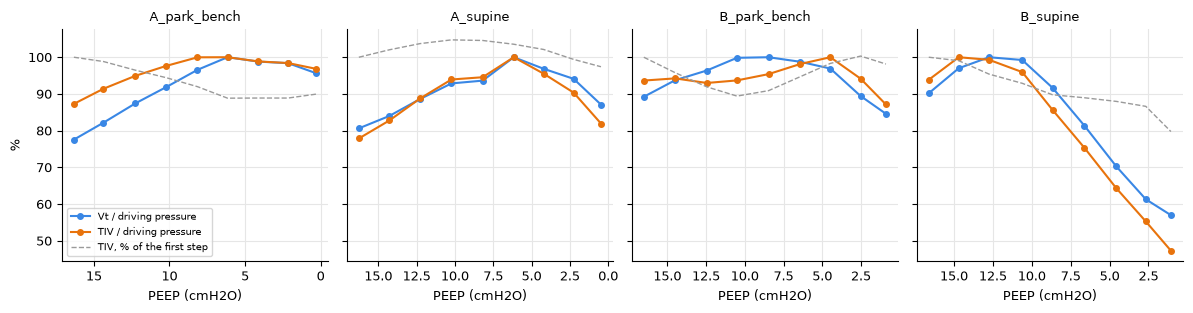

,compliance (mL/cmH2O),"best PEEP, Vt / driving","best PEEP, TIV / driving"
A_park_bench,53-68,6.2,6.2
A_supine,69-85,6.2,6.2
B_park_bench,36-43,8.5,4.5
B_supine,24-43,12.7,14.7


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, features) in zip(axes, trials.items()):
    steps = features.steps
    ax.plot(steps.peep, steps.compliance_ml_pct_of_best, "o-", color=BLUE, ms=4, label="Vt / driving pressure")
    ax.plot(steps.peep, steps.compliance_pct_of_best, "o-", color=ORANGE, ms=4, label="TIV / driving pressure")
    ax.plot(steps.peep, 100 * steps.tiv / steps.tiv.iloc[0], "--", color=GREY, lw=1, label="TIV, % of the first step")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("PEEP (cmH2O)")
    ax.invert_xaxis()
axes[0].set_ylabel("%")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

pd.DataFrame({name: {"compliance (mL/cmH2O)": f"{f.steps.compliance_ml.min():.0f}-{f.steps.compliance_ml.max():.0f}",
                     "best PEEP, Vt / driving": round(summary_value(f, "best_peep_compliance_ml"), 1),
                     "best PEEP, TIV / driving": round(summary_value(f, "best_peep_compliance"), 1)}
              for name, f in trials.items()}).T

Compliance 24-85 mL/cmH2O; best PEEP in the table. At the same tidal volume, the TIV of the slice is 80-105 % of
the first step (grey line).

Regional compliance in mL/cmH2O (`features.step_regions`), ventral/dorsal halves (cut on the lung) and right/left
halves (cut at the image midline):

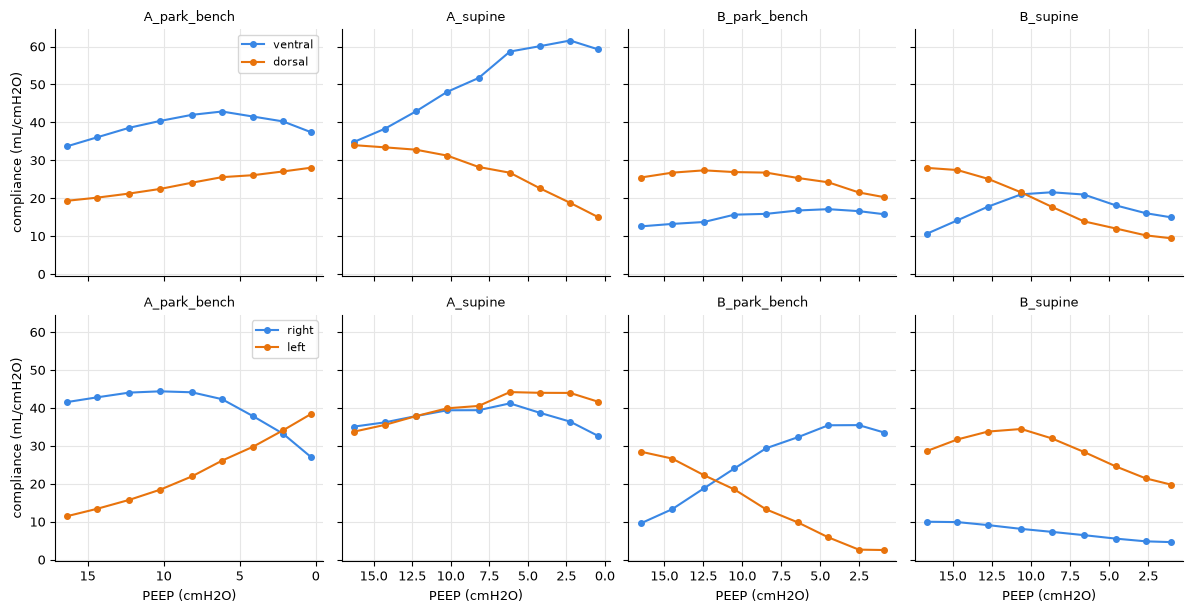

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2), sharey=True, sharex="col")
for row, pair in enumerate([("ventral", "dorsal"), ("right", "left")]):
    for ax, (name, features) in zip(axes[row], trials.items()):
        regions = features.step_regions.merge(features.steps[["step", "peep"]], on="step")
        for region, color in zip(pair, (BLUE, ORANGE)):
            values = regions[regions.region == region]
            ax.plot(values.peep, values.compliance_ml, "o-", color=color, ms=4, label=region)
        ax.set_title(name, fontsize=9)
        if row == 0:
            ax.invert_xaxis()
        else:
            ax.set_xlabel("PEEP (cmH2O)")
    axes[row, 0].set_ylabel("compliance (mL/cmH2O)")
    axes[row, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Supine, as PEEP falls, dorsal compliance falls and ventral compliance rises (crossing near PEEP 16 in A, 10.6 in B).
In park bench the two halves that cross are right and left (near PEEP 2.5 in A, 12.5 in B).

**Decision:** both global compliances are kept (Vt / driving pressure and TIV / driving pressure); every region gets
its TIV and compliance, in EIT units and, with a tidal volume, in mL.

## 4. PEEP trials

### Costa collapse and overdistension

Costa et al., Intensive Care Med 2009, DOI: 10.1007/s00134-009-1447-y; formulas as reported by Shono and Kotani,
J Intensive Care 2019, DOI: 10.1186/s40560-019-0358-4:

- compliance of a pixel at a step = median pixel TIV of the analysed breaths / driving pressure of the step;
- each pixel has its best compliance, at its best PEEP;
- at a lower PEEP than its best, the loss of compliance as % of its best (at most 100 %) is collapse; at a higher PEEP,
  overdistension;
- collapse (overdistension) of a step = mean of the pixel %, weighted by the best compliance of each pixel;
- crossing PEEP = where the two curves cross.

Check on two pixels: pixel 1 has its best at PEEP 16 and half of it at 6; pixel 2 its best at 6, three times the best
of pixel 1. Expected: collapse 12.5 % at PEEP 6 (weight 1 of 4), overdistension 37.5 % at PEEP 16 (weight 3 of 4).

In [7]:
peep = np.array([16.0, 6.0])
pixels = np.array([[[1.0, 1.5]], [[0.5, 3.0]]])
collapse_and_overdistension(pixels, peep, np.ones((1, 2), dtype=bool)).assign(peep=peep)

,collapse,overdistension,peep
0,0.0,37.5,16.0
1,12.5,0.0,6.0


On the four trials (`features.steps`, crossing in `features.summary`):

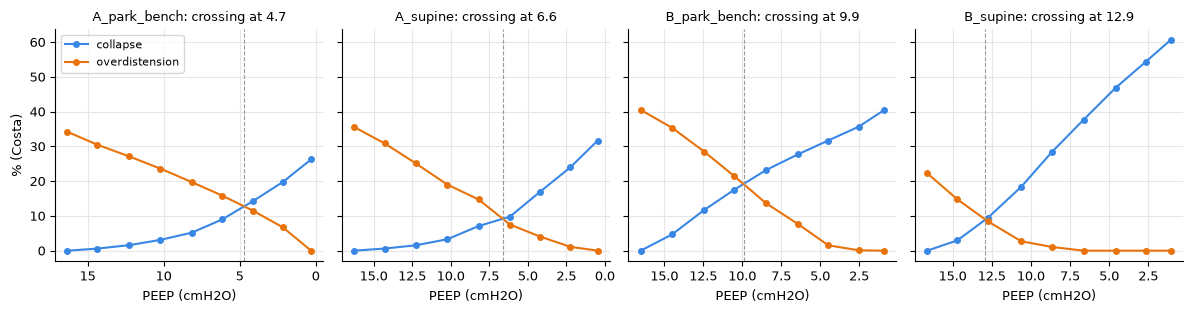

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, features) in zip(axes, trials.items()):
    steps, crossing = features.steps, summary_value(features, "crossing_peep")
    ax.plot(steps.peep, steps.collapse, "o-", color=BLUE, ms=4, label="collapse")
    ax.plot(steps.peep, steps.overdistension, "o-", color=ORANGE, ms=4, label="overdistension")
    ax.axvline(crossing, color=GREY, lw=0.8, ls="--")
    ax.set_title(f"{name}: crossing at {crossing:.1f}", fontsize=9)
    ax.set_xlabel("PEEP (cmH2O)")
    ax.invert_xaxis()
axes[0].set_ylabel("% (Costa)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Crossing PEEP: 4.7 (A park bench), 6.6 (A supine), 9.9 (B park bench), 12.9 (B supine).

### Changes between steps

For the statistics across patients, vs the previous step and vs the first: the change of EELI **in tidal volumes** and
in mL, converted with the TIV and the tidal volume of the step at the lower PEEP of the two (Wang et al., Med Sci Monit
2020, DOI: 10.12659/MSM.922609), and the change of compliance in points of % of the best step. Collapse and
overdistension are read on their curves (one value per step). Trial A supine, step by step:

In [9]:
columns = ["peep", "collapse", "overdistension", "d_eeli_tiv_vs_previous", "d_eeli_ml_vs_previous",
           "d_compliance_pct_of_best_vs_previous"]
trials["A_supine"].steps[columns].round(2)

,peep,collapse,overdistension,d_eeli_tiv_vs_previous,d_eeli_ml_vs_previous,d_compliance_pct_of_best_vs_previous
0,16.27,0.00,35.59,NaN,NaN,NaN
1,14.28,0.62,30.85,-0.40,-220.51,4.90
2,12.27,1.55,25.13,-0.48,-266.00,6.01
3,10.23,3.28,19.03,-0.56,-308.52,5.15
4,8.19,7.08,14.72,-0.56,-307.85,0.62
5,6.16,9.79,7.52,-0.60,-332.18,5.45
6,4.21,16.92,4.07,-0.64,-349.96,-4.48
7,2.25,23.93,1.12,-0.55,-300.48,-5.16
8,0.47,31.66,0.00,-0.51,-280.82,-8.41


A supine: each step lowers EELI by 0.40-0.64 tidal volumes (220-350 mL); compliance changes by -8.4 to +6.0
points of % of the best; collapse rises from 0 to 32 %, overdistension falls from 36 to 0 %.

### Recruitment-to-inflation ratio

R/I (Chen et al., Am J Respir Crit Care Med 2020, DOI: 10.1164/rccm.201902-0334OC) between the step nearest to PEEP 15
and the step nearest to PEEP 5 at least 10 below it; the change of end-expiratory lung volume from EIT as in Wang 2020:

- dEELV = (EELI_high - EELI_low) x Vt_low / TIV_low;
- recruited volume = dEELV - C_low x dPEEP, with C_low = Vt_low / driving pressure_low;
- R/I = (recruited volume / dPEEP) / C_low = (EELI_high - EELI_low) / (C_EIT,low x dPEEP) - 1: the tidal volume
  cancels, so R/I needs only EIT and the driving pressure; a region uses its own EELI and compliance.

Global and regional values (`features.summary`):

In [10]:
table = {}
for name, features in trials.items():
    table[name] = {"PEEP high": summary_value(features, "ri_peep_high"),
                   "PEEP low": summary_value(features, "ri_peep_low"),
                   "R/I": summary_value(features, "ri"),
                   "recruited (mL)": summary_value(features, "recruited_volume_ml"),
                   **{f"R/I {region}": summary_value(features, "ri", region)
                      for region in ["ventral", "dorsal", "right", "left"]}}
pd.DataFrame(table).T.round(2)

,PEEP high,PEEP low,R/I,recruited (mL),R/I ventral,R/I dorsal,R/I right,R/I left
A_park_bench,14.37,4.12,0.73,508.18,0.71,0.76,0.84,0.60
A_supine,14.28,4.21,0.91,755.78,0.75,1.34,0.89,0.92
B_park_bench,14.50,4.48,1.42,587.55,1.48,1.39,0.77,5.18
B_supine,14.69,4.57,1.31,400.88,0.91,1.92,1.60,1.25


R/I 0.73-1.42 between the steps near PEEP 14.3-14.7 and 4.1-4.6; recruited volume 400-760 mL. By region 0.60-1.92,
and 5.18 in the left half of B park bench, whose compliance at the low PEEP is about 3 mL/cmH2O.

**Decision:** Costa collapse, overdistension and crossing PEEP for each trial; changes vs the previous and the first
step for EELI (in tidal volumes and in mL) and compliance; R/I and recruited volume, global and by region.

## 5. Decisions

| § | Decision | fastEIT |
|---|----------|---------|
| 1 | EELI at the start of the breath, TIV = peak - start, one sample at the layer 2 frames (TREND, eitprocessing) | columns `eeli`, `tiv` |
| 2 | Share by region, GI, centre of ventilation on the image grid | `breath_indices.global_inhomogeneity`, `centre_of_ventilation`; `regions.share` |
| 3 | Compliance: TIV / driving pressure and tidal volume / driving pressure, both kept; per step from the median TIV and the driving pressure of the step | columns `compliance`, `compliance_ml` |
| 3 | Region: TIV and compliance (sum of its pixels), in mL with a tidal volume (share x Vt) | `regions`, `step_regions` |
| 4 | Costa collapse and overdistension (loss at most 100 %), crossing PEEP | `costa.collapse_and_overdistension`, `crossing_peep` |
| 4 | Changes vs the previous and the first step: EELI (calibrated at the lower PEEP) and compliance | columns `d_*` of `PeepTrialFeatures.steps` |
| 4 | R/I and recruited volume between the steps nearest to PEEP 15 and 5 (drop ≥ 10), global and by region | `features.recruitment`, `AnalysisConfig`, `summary` |
| - | Tidal recordings: median and quartiles over the valid breaths | `TidalFeatures.summary` |
| 3 | Tidal volume: typed for each step, typed for the recording, or measured, in this order | `segment_peep_trial(tidal_volumes=...)`, `RecordingContext.tidal_volume_ml` |

Assumptions of the values in mL: compliance of the respiratory system, with the same driving pressure for every
region; the mL of a region are the tidal volume shared as in the imaged slice; the change of EELI in mL assumes the same
impedance per mL for the tidal and the end-expiratory change (Hinz et al., Intensive Care Med 2003, DOI:
10.1007/s00134-002-1555-4, show the linear relation of the changes); R/I mixes recruitment and overdistension (Zhao et
al., Crit Care 2023, DOI: 10.1186/s13054-023-04520-8).

Limits: two patients, decremental trials only; tidal volume as set, not measured; Costa implemented from its published
formulas, not checked against another implementation; one lung mask for the whole trial.